<a href="https://colab.research.google.com/github/IvanAriciaga/PIA-Modelado-1/blob/main/PIA_Modelado_Robot_2GDL_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

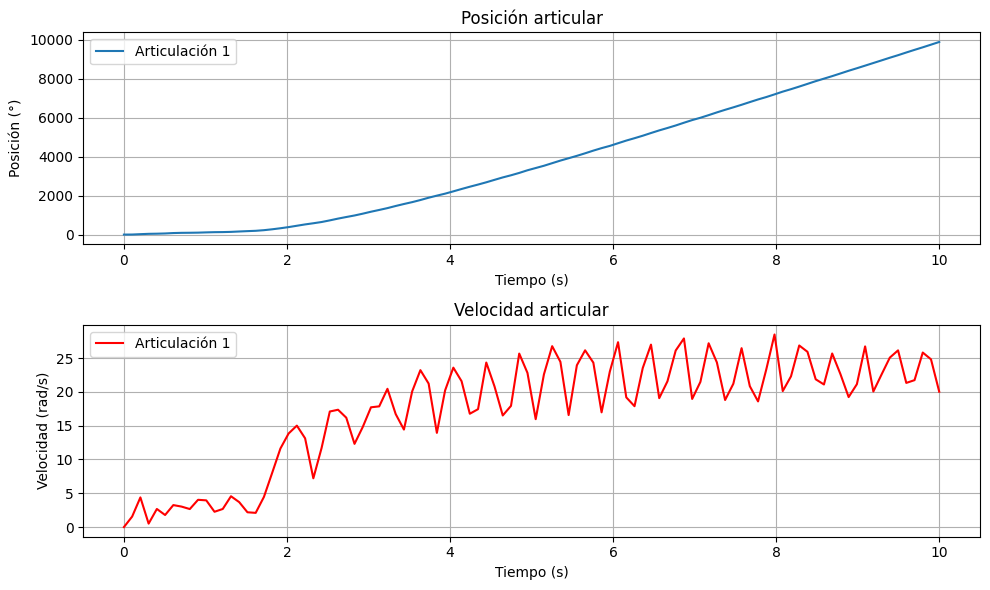

SIMULACIÓN FINALIZADA CORRECTAMENTE
Tiempo inicial: 0.0 s
Tiempo final: 10.0 s
Número de puntos calculados: 100
Posición final: 9893.212396417875 grados
Velocidad final: 20.026354608383503 rad/s


In [3]:

# ============================================================
# AF7 - PROYECTO FINAL
# MODELADO Y SIMULACIÓN DE ROBOT PLANAR DE 2 GDL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ------------------------------------------------------------
# Modelo dinámico del robot de dos grados de libertad
# ------------------------------------------------------------

def robot2gdl(t, x):

    # Vector de posición articular
    q = np.array([x[0], x[1]])

    # Vector de velocidad articular
    qp = np.array([x[2], x[3]])

    # Matriz de inercia
    M = np.array([
        [3.117 + 0.2 * np.cos(q[1]),
         0.108 + 0.1 * np.cos(q[1])],

        [0.108 + 0.1 * np.cos(q[1]),
         0.108]
    ])

    # Matriz de fuerzas centrípetas y de Coriolis
    C = np.array([
        [-0.2 * np.sin(q[1]) * qp[1],
         -0.1 * np.sin(q[1]) * qp[1]],

        [0.1 * np.sin(q[1]) * qp[0],
         0.0]
    ])

    # Vector de pares gravitacionales
    par_grav = np.array([
        39.3 * np.sin(q[0]) +
        1.95 * np.sin(q[0] + q[1]),

        1.95 * np.sin(q[0] + q[1])
    ])

    # Vector de fuerzas de fricción viscosa
    fr = np.array([
        1.86 * qp[0] + 1.93 * np.sin(qp[0]),
        0.16 * qp[1] + 0.39 * np.sin(qp[1])
    ])

    # Torque aplicado
    tau = np.array([
        11 * (1 - np.exp(-1.8 * t))
        + 32.80
        + 56 * np.sin(16 * t + 0.1)
        + 12 * np.sin(20 * t + 0.15),

        1 - np.exp(-1.8 * t)
        + 12
        + 8 * np.sin(26 * t + 0.28)
        + 8 * np.sin(12 * t + 0.34)
    ])

    # Cálculo de la aceleración articular
    # Se resuelve M * aceleracion = fuerzas
    fuerzas = tau - C @ qp - par_grav - fr
    qp2 = np.linalg.solve(M, fuerzas)

    return [qp[0], qp[1], qp2[0], qp2[1]]


# ------------------------------------------------------------
# Simulación
# ------------------------------------------------------------

t_span = (0, 10)             # Tiempo de simulación
x0 = [0, 0, 0, 0]           # Condiciones iniciales
t_eval = np.linspace(0, 10, 100)

sol = solve_ivp(
    robot2gdl,
    t_span,
    x0,
    t_eval=t_eval,
    method='RK45',
    rtol=1e-6,
    atol=1e-8
)

# Verificación de la simulación
if not sol.success:
    raise RuntimeError("Error en la simulación: " + sol.message)

# ------------------------------------------------------------
# Obtención de coordenadas
# ------------------------------------------------------------

theta = np.rad2deg(sol.y[0])       # Posición en grados
theta_dot = sol.y[2]               # Velocidad en rad/s

# ------------------------------------------------------------
# Gráficas de resultados
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

# Gráfica de posición articular
plt.subplot(2, 1, 1)
plt.plot(sol.t, theta, label='Articulación 1')
plt.xlabel('Tiempo (s)')
plt.ylabel('Posición (°)')
plt.title('Posición articular')
plt.grid(True)
plt.legend()

# Gráfica de velocidad articular
plt.subplot(2, 1, 2)
plt.plot(sol.t, theta_dot, 'r', label='Articulación 1')
plt.xlabel('Tiempo (s)')
plt.ylabel('Velocidad (rad/s)')
plt.title('Velocidad articular')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Resultados finales
# ------------------------------------------------------------

print("SIMULACIÓN FINALIZADA CORRECTAMENTE")
print("Tiempo inicial:", sol.t[0], "s")
print("Tiempo final:", sol.t[-1], "s")
print("Número de puntos calculados:", len(sol.t))
print("Posición final:", theta[-1], "grados")
print("Velocidad final:", theta_dot[-1], "rad/s")


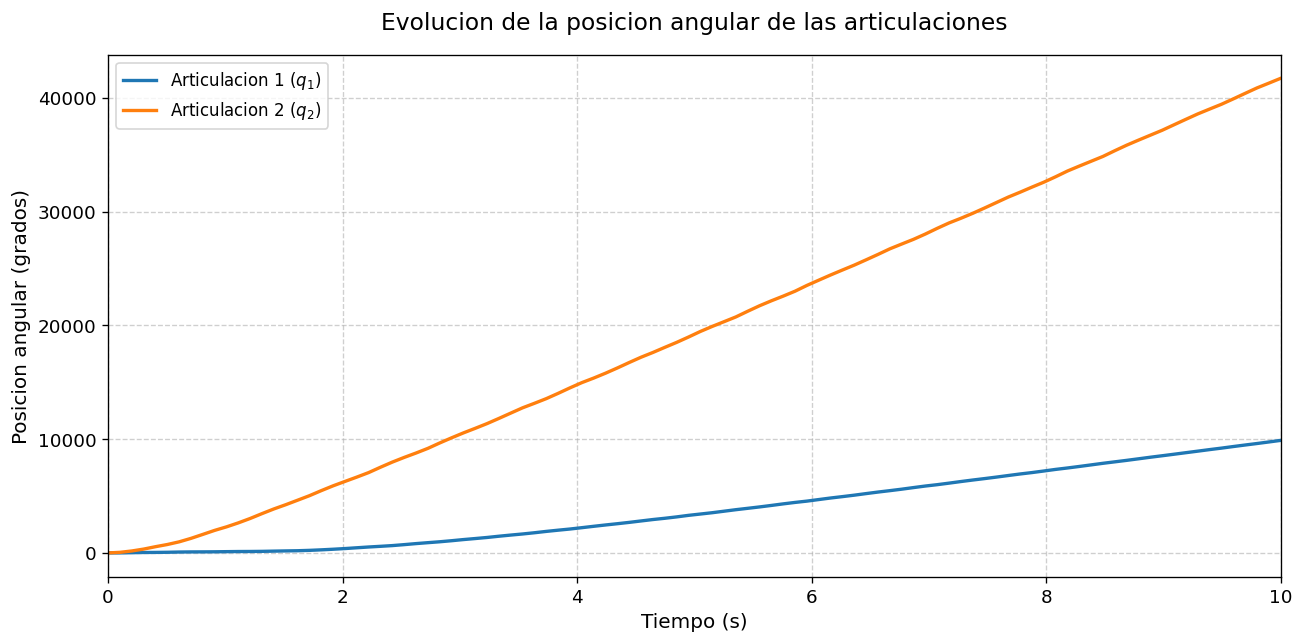

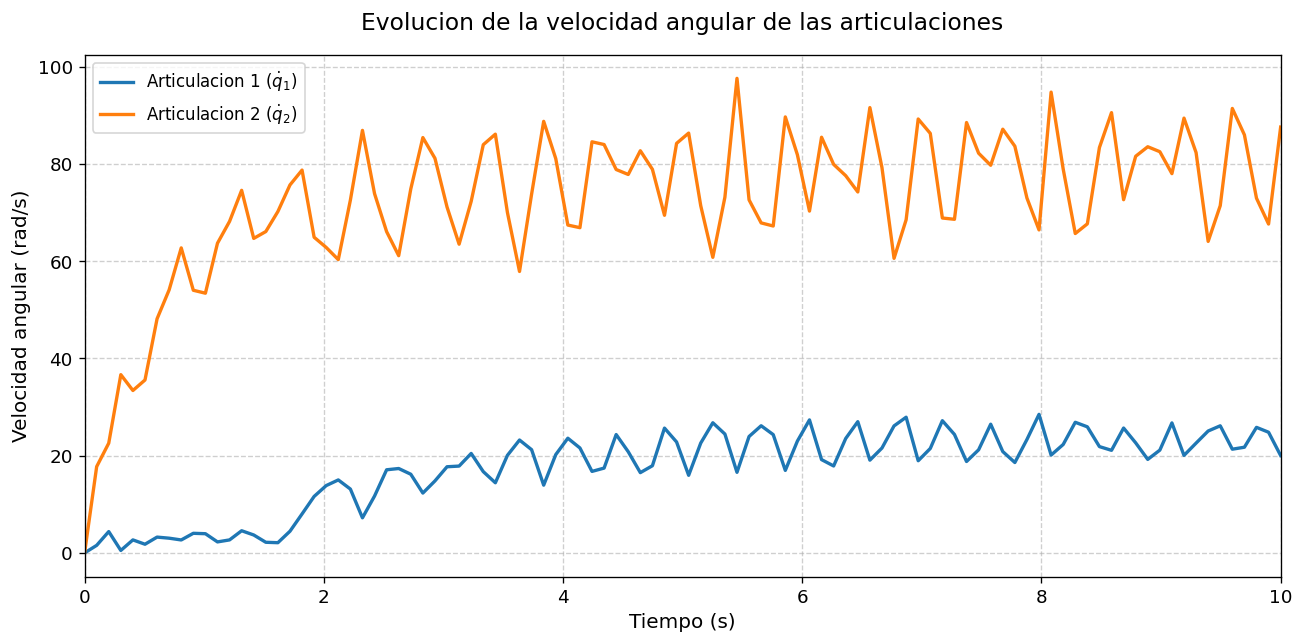

GRAFICAS FINALES GENERADAS CORRECTAMENTE
----------------------------------------
1. Figura_1_Posicion_Angular.png
2. Figura_2_Velocidad_Angular.png
----------------------------------------
Intervalo de simulacion: 0.0 a 10.0 segundos
Numero de puntos: 100


In [4]:

# ============================================================
# GRAFICAS FINALES DE LA SIMULACION DEL ROBOT PLANAR DE 2 GDL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Verificar que la simulacion anterior se haya ejecutado
if 'sol' not in globals() or not sol.success:
    raise RuntimeError(
        "Primero debes ejecutar la celda de simulacion completa."
    )

# Recuperar los resultados de la simulacion original
t = sol.t

q1_grados = np.rad2deg(sol.y[0])
q2_grados = np.rad2deg(sol.y[1])

dq1 = sol.y[2]
dq2 = sol.y[3]

# Configuracion general de las graficas
plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'figure.dpi': 120,
    'savefig.dpi': 300
})

# ============================================================
# FIGURA 1. POSICION ANGULAR
# ============================================================

fig1, ax1 = plt.subplots(figsize=(11, 5.5))

ax1.plot(
    t, q1_grados,
    label='Articulacion 1 ($q_1$)',
    linewidth=2
)

ax1.plot(
    t, q2_grados,
    label='Articulacion 2 ($q_2$)',
    linewidth=2
)

ax1.set_title(
    'Evolucion de la posicion angular de las articulaciones',
    pad=15
)

ax1.set_xlabel('Tiempo (s)')
ax1.set_ylabel('Posicion angular (grados)')

ax1.set_xlim(0, 10)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='best', frameon=True)

fig1.tight_layout()
fig1.savefig('Figura_1_Posicion_Angular.png', bbox_inches='tight')
plt.show()


# ============================================================
# FIGURA 2. VELOCIDAD ANGULAR
# ============================================================

fig2, ax2 = plt.subplots(figsize=(11, 5.5))

ax2.plot(
    t, dq1,
    label='Articulacion 1 ($\\dot{q}_1$)',
    linewidth=2
)

ax2.plot(
    t, dq2,
    label='Articulacion 2 ($\\dot{q}_2$)',
    linewidth=2
)

ax2.set_title(
    'Evolucion de la velocidad angular de las articulaciones',
    pad=15
)

ax2.set_xlabel('Tiempo (s)')
ax2.set_ylabel('Velocidad angular (rad/s)')

ax2.set_xlim(0, 10)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='best', frameon=True)

fig2.tight_layout()
fig2.savefig('Figura_2_Velocidad_Angular.png', bbox_inches='tight')
plt.show()


# ============================================================
# GUARDADO DE RESULTADOS
# ============================================================

print("GRAFICAS FINALES GENERADAS CORRECTAMENTE")
print("----------------------------------------")
print("1. Figura_1_Posicion_Angular.png")
print("2. Figura_2_Velocidad_Angular.png")
print("----------------------------------------")
print("Intervalo de simulacion:", t[0], "a", t[-1], "segundos")
print("Numero de puntos:", len(t))
